In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

file_path = Path(
    "../05_Clean_Data/marketing_data_clean.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 46)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Income_Was_Missing,Income_Imputed,Education_Standardized,Marital_Status_Group,Country_Standardized,Income_Is_Outlier,Total_Spending,Total_Purchases,Total_Children,Total_Accepted_Campaigns,Customer_Age_Estimated,Age_Group,Income_Group,Enrollment_Year,Enrollment_Month,Enrollment_Quarter,Enrollment_Month_Name,Customer_Tenure_Days
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,Spain,0,84835.0,Graduate,Divorced,Spain,0,1190,14,0,1,44,35-44,High Income,2014,6,2,June,14
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,Canada,0,57091.0,Graduate,Single,Canada,0,577,17,0,2,53,45-54,Upper-Middle Income,2014,6,2,June,15
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,USA,0,67267.0,Graduate,Married,Usa,0,251,10,1,0,56,55-64,Upper-Middle Income,2014,5,2,May,48
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,Australia,0,32474.0,Graduate,Partnered,Australia,0,11,3,2,0,47,45-54,Low Income,2014,5,2,May,50
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,Spain,0,21474.0,Graduate,Single,Spain,0,91,6,1,2,25,25-34,Low Income,2014,4,2,April,83


In [2]:
channel_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

channel_names = {
    "NumWebPurchases": "Web",
    "NumCatalogPurchases": "Catalog",
    "NumStorePurchases": "Store"
}

display(
    df[channel_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
NumWebPurchases,2240.0,4.084821,2.778714,0.0,2.0,4.0,6.0,27.0
NumCatalogPurchases,2240.0,2.662054,2.923101,0.0,0.0,2.0,4.0,28.0
NumStorePurchases,2240.0,5.790179,3.250958,0.0,3.0,5.0,8.0,13.0


In [3]:
channel_purchases = (
    df[channel_columns]
    .sum()
    .reset_index()
)

channel_purchases.columns = [
    "Channel",
    "Total_Purchases"
]

channel_purchases["Channel"] = (
    channel_purchases["Channel"]
    .replace(channel_names)
)

channel_purchases = (
    channel_purchases.sort_values(
        "Total_Purchases",
        ascending=False
    )
)

display(channel_purchases)

,Channel,Total_Purchases
2,Store,12970
0,Web,9150
1,Catalog,5963


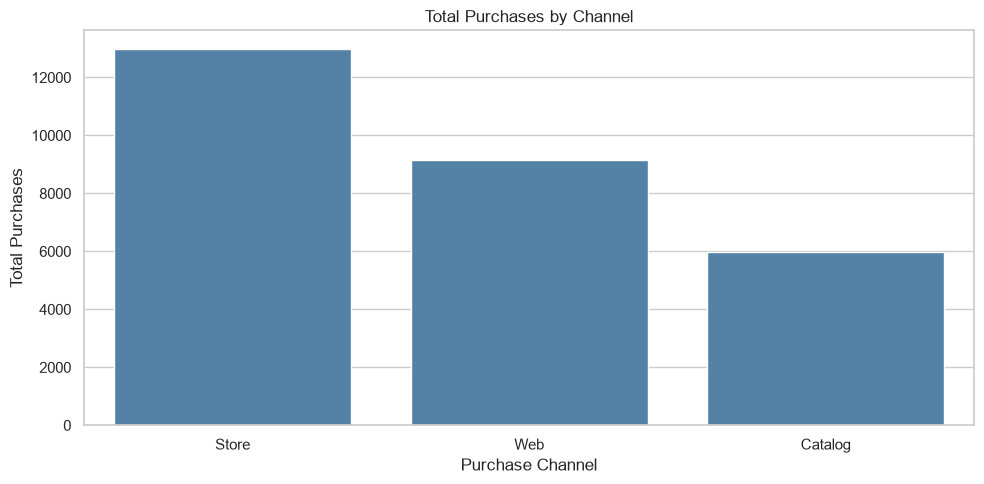

In [4]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=channel_purchases,
    x="Channel",
    y="Total_Purchases",
    color="steelblue"
)

plt.title("Total Purchases by Channel")
plt.xlabel("Purchase Channel")
plt.ylabel("Total Purchases")

plt.tight_layout()
plt.show()

In [5]:
total_channel_purchases = (channel_purchases["Total_Purchases"].sum())

channel_purchases["Purchase_Share"] = (
    channel_purchases["Total_Purchases"]/total_channel_purchases*100
    ).round(2)

display(channel_purchases)

,Channel,Total_Purchases,Purchase_Share
2,Store,12970,46.18
0,Web,9150,32.58
1,Catalog,5963,21.23


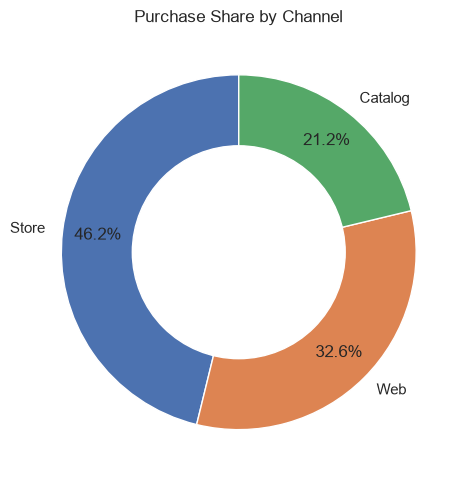

In [6]:
plt.figure(figsize=(10, 5))

plt.pie(
    channel_purchases["Total_Purchases"],
    labels=channel_purchases["Channel"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8
)
centre_circle = plt.Circle(
    (0, 0),
    0.60,
    fc="white"
)

plt.gca().add_artist(centre_circle)

plt.title("Purchase Share by Channel")

plt.tight_layout()
plt.show()

In [7]:
channel_customers = (
    (df[channel_columns] > 0)
    .sum()
    .reset_index()
)

channel_customers.columns = [
    "Channel",
    "Customer_Count"
]

channel_customers["Channel"] = (
    channel_customers["Channel"]
    .replace(channel_names)
)

display(channel_customers)

,Channel,Customer_Count
0,Web,2191
1,Catalog,1654
2,Store,2225


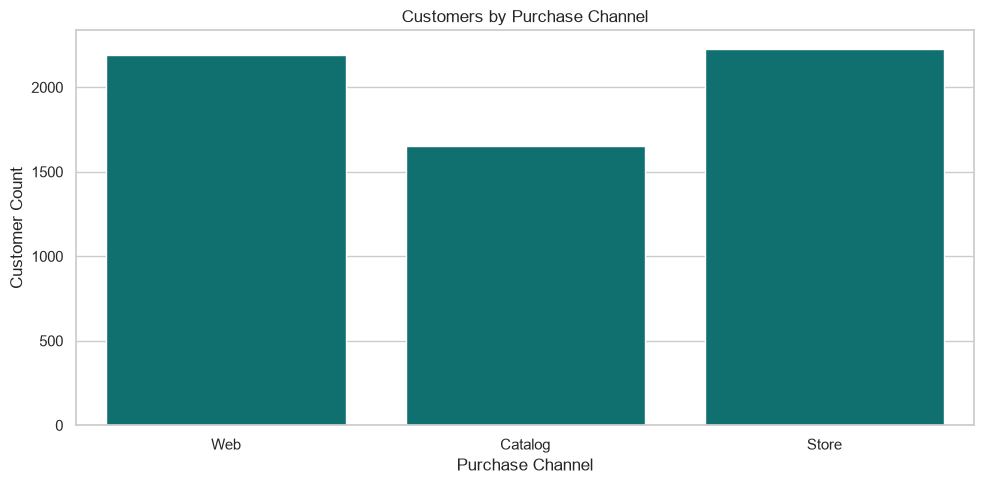

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=channel_customers,
    x="Channel",
    y="Customer_Count",
    color="teal"
)

plt.title("Customers by Purchase Channel")
plt.xlabel("Purchase Channel")
plt.ylabel("Customer Count")

plt.tight_layout()
plt.show()

In [9]:
channel_performance = channel_purchases.merge(
    channel_customers,
    on="Channel",
    how="left"
)

channel_performance["Avg_Purchases_Per_User"] = (
    channel_performance["Total_Purchases"]
    / channel_performance["Customer_Count"].replace(0, np.nan)
)

display(channel_performance.round(2))

,Channel,Total_Purchases,Purchase_Share,Customer_Count,Avg_Purchases_Per_User
0,Store,12970,46.18,2225,5.83
1,Web,9150,32.58,2191,4.18
2,Catalog,5963,21.23,1654,3.61


In [10]:
max_purchases = df[channel_columns].max(axis=1)

tie_count = df[channel_columns].eq(
    max_purchases,
    axis=0
).sum(axis=1)

df["Preferred_Channel"] = np.select(
    [
        max_purchases.eq(0),
        tie_count.gt(1)
    ],
    [
        "No Purchases",
        "Multiple Channels"
    ],
    default=df[channel_columns]
        .idxmax(axis=1)
        .replace(channel_names)
)

display(
    df[
        [
            "ID",
            "NumWebPurchases",
            "NumCatalogPurchases",
            "NumStorePurchases",
            "Preferred_Channel"
        ]
    ].head(10)
)

,ID,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Preferred_Channel
0,1826,4,4,6,Store
1,1,7,3,7,Multiple Channels
2,10476,3,2,5,Store
3,1386,1,0,2,Store
4,5371,3,1,2,Web
5,7348,4,7,5,Catalog
6,4073,10,10,7,Multiple Channels
7,1991,2,1,3,Store
8,4047,6,2,9,Store
9,9477,6,2,9,Store


In [11]:
preferred_channel_distribution = (
    df["Preferred_Channel"]
    .value_counts()
    .reset_index()
)

preferred_channel_distribution.columns = [
    "Preferred_Channel",
    "Customer_Count"
]

display(preferred_channel_distribution)

,Preferred_Channel,Customer_Count
0,Store,1478
1,Web,325
2,Multiple Channels,294
3,Catalog,137
4,No Purchases,6


In [13]:
age_channel_analysis = (
    df.groupby(
        "Age_Group",
        observed=True
    )[channel_columns]
    .mean()
)

age_channel_analysis = (
    age_channel_analysis
    .rename(columns=channel_names)
)

display(age_channel_analysis.round(2))

,Web,Catalog,Store
Age_Group,,,
18-24,3.59,3.61,5.75
25-34,3.48,2.18,5.20
35-44,3.82,2.29,5.43
45-54,4.38,2.73,6.07
55-64,4.47,3.12,6.23
65+,5.23,4.07,7.18


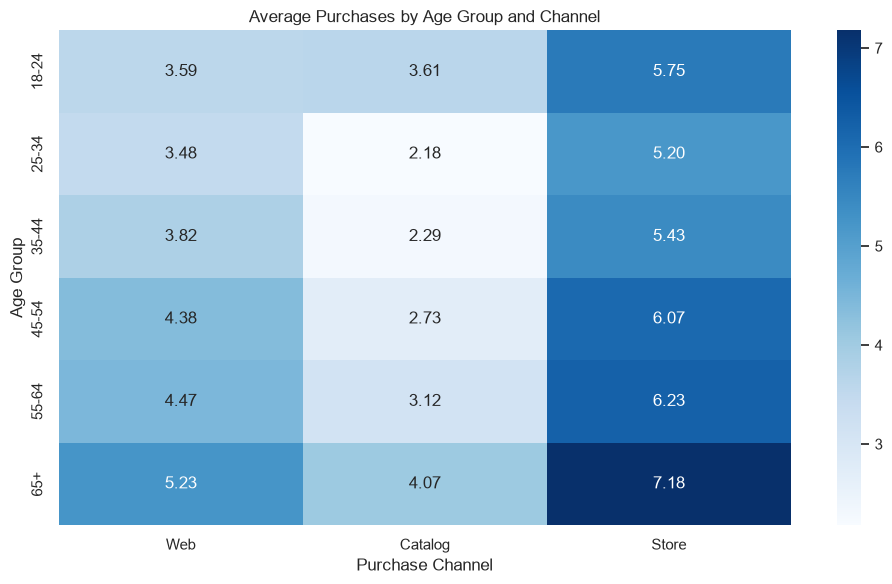

In [14]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    age_channel_analysis,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Average Purchases by Age Group and Channel")
plt.xlabel("Purchase Channel")
plt.ylabel("Age Group")

plt.tight_layout()
plt.show()

In [15]:
income_channel_analysis = (
    df.groupby(
        "Income_Group",
        observed=True
    )[channel_columns]
    .mean()
)

income_channel_analysis = (
    income_channel_analysis
    .rename(columns=channel_names)
)

display(income_channel_analysis.round(2))

,Web,Catalog,Store
Income_Group,,,
High Income,5.29,5.70,8.34
Low Income,2.01,0.48,2.96
Lower-Middle Income,3.40,1.17,4.21
Upper-Middle Income,5.64,3.34,7.70


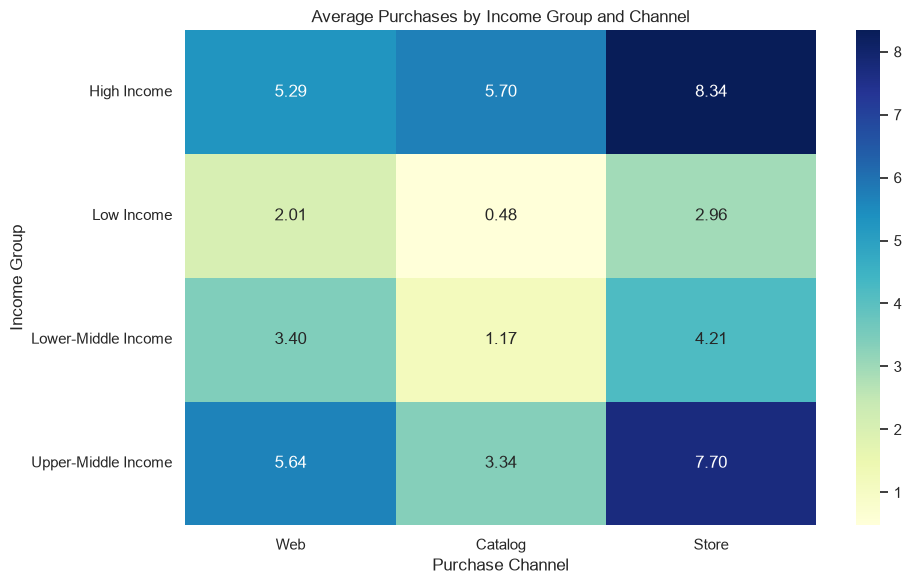

In [16]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    income_channel_analysis,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Purchases by Income Group and Channel")
plt.xlabel("Purchase Channel")
plt.ylabel("Income Group")

plt.tight_layout()
plt.show()

In [17]:
total_deal_purchases = (
    df["NumDealsPurchases"].sum()
)

total_purchases = (
    df["Total_Purchases"].sum()
)

discount_purchase_share = (
    total_deal_purchases / total_purchases * 100
    if total_purchases > 0
    else np.nan
)

print("Total Deal Purchases:", total_deal_purchases)

print("Total Purchases:", total_purchases)

print(
    "Discount Purchase Share:",
    round(discount_purchase_share, 2),
    "%"
)

Total Deal Purchases: 5208
Total Purchases: 28083
Discount Purchase Share: 18.55 %


In [18]:
invalid_deal_records = df[
    df["NumDealsPurchases"] > df["Total_Purchases"]
]

print(
    "Deal Purchases > Total Purchases:",
    len(invalid_deal_records)
)

Deal Purchases > Total Purchases: 3


In [24]:
invalid_deal_records = df[
    df["NumDealsPurchases"] > df["Total_Purchases"]
]

display(
    invalid_deal_records[
        [
            "ID",
            "NumDealsPurchases",
            "NumWebPurchases",
            "NumCatalogPurchases",
            "NumStorePurchases",
            "Total_Purchases"
        ]
    ]
)

,ID,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Total_Purchases
663,9931,15,0,0,0,0
1416,10749,15,0,1,0,1
1466,6862,15,0,0,0,0


In [25]:
print("Affected Customers:", len(invalid_deal_records))

print(
    "Affected Percentage:",
    round(len(invalid_deal_records) / len(df) * 100, 2),
    "%"
)

Affected Customers: 3
Affected Percentage: 0.13 %


In [26]:
invalid_deal_records = invalid_deal_records.copy()

invalid_deal_records["Difference"] = (
    invalid_deal_records["NumDealsPurchases"]
    - invalid_deal_records["Total_Purchases"]
)

display(
    invalid_deal_records[
        [
            "ID",
            "NumDealsPurchases",
            "Total_Purchases",
            "Difference"
        ]
    ].sort_values("Difference", ascending=False)
)

,ID,NumDealsPurchases,Total_Purchases,Difference
663,9931,15,0,15
1466,6862,15,0,15
1416,10749,15,1,14


In [27]:
df["Deal_Purchase_Issue"] = np.where(
    df["NumDealsPurchases"] > df["Total_Purchases"],
    1,
    0
)

print(
    "Flagged Customers:",
    df["Deal_Purchase_Issue"].sum()
)

Flagged Customers: 3


In [28]:
display(
    df.loc[
        df["Deal_Purchase_Issue"] == 1,
        [
            "ID",
            "NumDealsPurchases",
            "Total_Purchases",
            "Deal_Purchase_Issue"
        ]
    ]
)

,ID,NumDealsPurchases,Total_Purchases,Deal_Purchase_Issue
663,9931,15,0,1
1416,10749,15,1,1
1466,6862,15,0,1


In [29]:
display(
    df.loc[
        df["Deal_Purchase_Issue"] == 1,
        [
            "ID",
            "NumDealsPurchases",
            "Total_Purchases",
            "Total_Spending",
            "Recency",
            "NumWebVisitsMonth"
        ]
    ]
)

,ID,NumDealsPurchases,Total_Purchases,Total_Spending,Recency,NumWebVisitsMonth
663,9931,15,0,9,29,19
1416,10749,15,1,178,62,19
1466,6862,15,0,8,65,20


In [30]:
purchase_spending_check = df[
    (df["Total_Purchases"] == 0) &
    (df["Total_Spending"] > 0)
]

print(
    "Customers with zero purchases but positive spending:",
    len(purchase_spending_check)
)

display(
    purchase_spending_check[
        [
            "ID",
            "Total_Purchases",
            "Total_Spending",
            "NumDealsPurchases"
        ]
    ]
)

Customers with zero purchases but positive spending: 6


,ID,Total_Purchases,Total_Spending,NumDealsPurchases
456,3955,0,6,0
663,9931,0,9,15
1291,11110,0,5,0
1466,6862,0,8,15
1826,5555,0,6,0
1925,11181,0,8,0


In [31]:
display(
    df["NumDealsPurchases"]
    .value_counts()
    .sort_index()
)

NumDealsPurchases
0      46
1     970
2     497
3     297
4     189
5      94
6      61
7      40
8      14
9       8
10      5
11      5
12      4
13      3
15      7
Name: count, dtype: int64

In [32]:
# DQ-004
df["Deal_Purchase_Issue"] = (
    df["NumDealsPurchases"] > df["Total_Purchases"]
).astype(int)

# DQ-005
df["Zero_Purchase_Spending_Issue"] = (
    (df["Total_Purchases"] == 0) &
    (df["Total_Spending"] > 0)
).astype(int)

# Ən azı bir problem olan müştəri
df["Has_Data_Quality_Issue"] = (
    (df["Deal_Purchase_Issue"] == 1) |
    (df["Zero_Purchase_Spending_Issue"] == 1)
).astype(int)

In [33]:
print(
    "DQ-004:",
    df["Deal_Purchase_Issue"].sum()
)

print(
    "DQ-005:",
    df["Zero_Purchase_Spending_Issue"].sum()
)

print(
    "Unique Flagged Customers:",
    df["Has_Data_Quality_Issue"].sum()
)

DQ-004: 3
DQ-005: 6
Unique Flagged Customers: 7


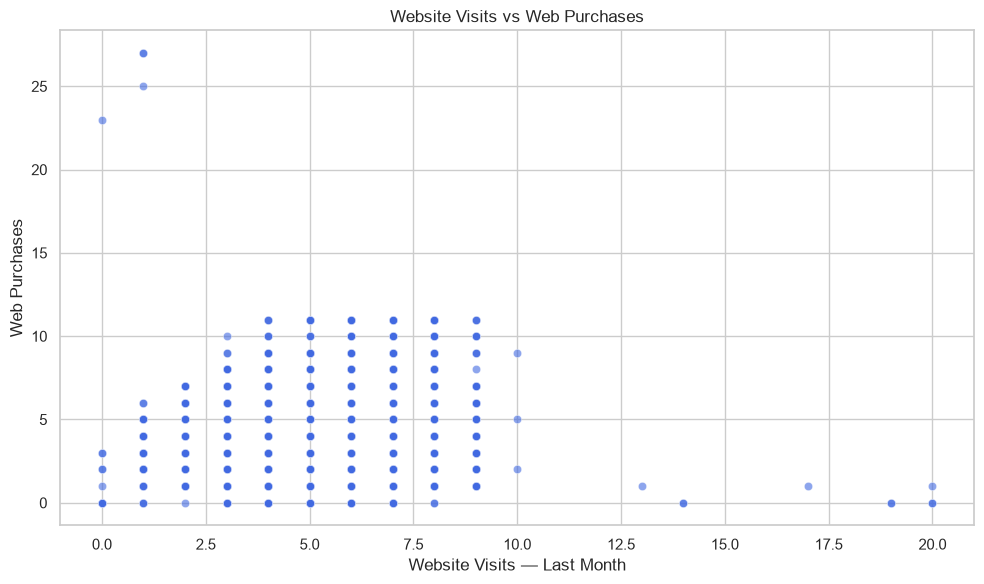

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="NumWebVisitsMonth",
    y="NumWebPurchases",
    alpha=0.6,
    color="royalblue"
)

plt.title("Website Visits vs Web Purchases")
plt.xlabel("Website Visits — Last Month")
plt.ylabel("Web Purchases")

plt.tight_layout()
plt.show()

In [20]:
correlation = df[
    ["NumWebVisitsMonth", "NumWebPurchases"]
].corr()

display(correlation)

,NumWebVisitsMonth,NumWebPurchases
NumWebVisitsMonth,1.000000,-0.055846
NumWebPurchases,-0.055846,1.000000


In [21]:
calculated_total_purchases = (
    df[channel_columns].sum(axis=1)
)

purchase_difference = (
    df["Total_Purchases"]
    - calculated_total_purchases
)

print(
    "Records with Purchase Difference:",
    (purchase_difference != 0).sum()
)

Records with Purchase Difference: 0


In [22]:
print(
    "Total Purchases from Channels:",
    df[channel_columns].sum().sum()
)

print(
    "Total Purchases from Derived Column:",
    df["Total_Purchases"].sum()
)

Total Purchases from Channels: 28083
Total Purchases from Derived Column: 28083


In [23]:
channel_performance_summary = (
    channel_performance[
        [
            "Channel",
            "Total_Purchases",
            "Purchase_Share",
            "Customer_Count",
            "Avg_Purchases_Per_User"
        ]
    ]
    .sort_values(
        "Total_Purchases",
        ascending=False
    )
)

display(
    channel_performance_summary.round(2)
)

,Channel,Total_Purchases,Purchase_Share,Customer_Count,Avg_Purchases_Per_User
0,Store,12970,46.18,2225,5.83
1,Web,9150,32.58,2191,4.18
2,Catalog,5963,21.23,1654,3.61
